# TP 4 · Entraîner son premier réseau

AI4I 2020, mêmes features et mêmes splits que les TP 1 et 3.
On remplace la logistic regression de scikit-learn par un **MLP** (multi-layer perceptron) écrit en **PyTorch**, et on écrit nous-mêmes la boucle d'entraînement.

## 0. Reprise : splits et preprocessing du TP 1

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import precision_score, recall_score, confusion_matrix

df = pd.read_csv("data/ai4i2020.csv")
TARGET = "Machine failure"
NUM_COLS = ["Torque [Nm]", "Air temperature [K]", "Process temperature [K]",
            "Rotational speed [rpm]", "Tool wear [min]"]
CAT_COLS = ["Type"]
X = df[NUM_COLS + CAT_COLS]
Y = df[TARGET]

# mêmes splits que les TP 1 et 3 : 60 / 20 / 20, stratifiés
X_train, X_tmp, Y_train, Y_tmp = train_test_split(X, Y, test_size=0.4, stratify=Y, random_state=42)
X_val, X_test, Y_val, Y_test   = train_test_split(X_tmp, Y_tmp, test_size=0.5, stratify=Y_tmp, random_state=42)

# même preprocessing, fit sur train uniquement
preprocess = ColumnTransformer([
    ("num", StandardScaler(), NUM_COLS),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_COLS),
])
preprocess.fit(X_train)
print(len(X_train), len(X_val), len(X_test), "| pannes en validation :", Y_val.sum())

6000 2000 2000 | pannes en validation : 68


## 1. Transformer les splits en tensors avec les bons dtypes

PyTorch ne travaille pas avec des DataFrames mais avec des **tensors**.
- **features** → `float32` : les poids du réseau sont en float32. Un tableau NumPy est en float64 par défaut, d'où l'erreur classique *« mat1 and mat2 must have the same dtype, but got Double and Float »*.
- **target** → `float32` aussi : `BCEWithLogitsLoss` compare des scores décimaux à des 0.0 / 1.0. Une target en entiers donne *« result type Float can't be cast to the desired output type Long »*.

In [2]:
X_train_t = torch.tensor(preprocess.transform(X_train), dtype=torch.float32)
y_train_t = torch.tensor(Y_train.to_numpy(), dtype=torch.float32)
X_val_t   = torch.tensor(preprocess.transform(X_val), dtype=torch.float32)
y_val_t   = torch.tensor(Y_val.to_numpy(), dtype=torch.float32)

for name, t in [("X_train_t", X_train_t), ("y_train_t", y_train_t),
                ("X_val_t", X_val_t), ("y_val_t", y_val_t)]:
    print(f"{name:<10} {str(tuple(t.shape)):<12} {t.dtype}")

X_train_t  (6000, 8)    torch.float32
y_train_t  (6000,)      torch.float32
X_val_t    (2000, 8)    torch.float32
y_val_t    (2000,)      torch.float32


**Batches :** on ne donne pas les 6000 lignes d'un coup. Le `DataLoader` découpe le train en **batches de 64 lignes**, mélangés à chaque epoch (`shuffle=True`). Chaque batch = **un update** des poids. Une **epoch** = tout le train vu une fois.

In [3]:
from torch.utils.data import TensorDataset, DataLoader

train_ds = TensorDataset(X_train_t, y_train_t)
torch.manual_seed(42)
train_loader = DataLoader(train_ds, batch_size=64, shuffle=True)

xb, yb = next(iter(train_loader))
print("batches par epoch :", len(train_loader))
print("un batch :", tuple(xb.shape), tuple(yb.shape), yb.dtype)

batches par epoch : 94
un batch : (64, 8) (64,) torch.float32


## 2. Construire le MLP et l'entraîner pendant 20 epochs

Architecture du cours : **8 entrées → 16 neurones cachés (ReLU) → 1 sortie**.
- `nn.Linear(8, 16)` : 16 neurones, chacun fait une somme pondérée des 8 features + un biais.
- `nn.ReLU()` : la non-linéarité (max(0, x)). Sans elle, empiler des Linear reviendrait à une seule Linear, donc à une logistic regression.
- `nn.Linear(16, 1)` : un seul score en sortie, le **logit** (avant sigmoid).

**Loss :** `BCEWithLogitsLoss` = sigmoid + binary cross-entropy en une seule étape, plus stable numériquement. Donc **pas de Sigmoid dans le modèle**.

**Optimizer :** `Adam`, learning rate 1e-3.

In [4]:
torch.manual_seed(42)
model = nn.Sequential(
    nn.Linear(8, 16),
    nn.ReLU(),
    nn.Linear(16, 1),
)
loss_fn = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

print(model)
print("parameters :", sum(p.numel() for p in model.parameters()), "(8×16+16 = 144, puis 16×1+1 = 17)")

Sequential(
  (0): Linear(in_features=8, out_features=16, bias=True)
  (1): ReLU()
  (2): Linear(in_features=16, out_features=1, bias=True)
)
parameters : 161 (8×16+16 = 144, puis 16×1+1 = 17)


### La training loop

Pour chaque batch, toujours les 5 mêmes gestes :
1. `optimizer.zero_grad()` : effacer les gradients du batch précédent (sinon ils s'additionnent, et le modèle apprend mal **sans aucune erreur**) ;
2. `model(xb)` : calculer les logits ;
3. `loss_fn(...)` : mesurer l'erreur ;
4. `loss.backward()` : calculer les gradients ;
5. `optimizer.step()` : mettre à jour les poids.

Après chaque epoch, on mesure la loss de **validation** en mode `model.eval()` et sous `torch.no_grad()` : **aucun backward, aucun step** sur la validation, elle ne sert qu'à mesurer.

`.squeeze(1)` transforme les logits de forme `[N, 1]` en `[N]`, la forme de la target.

## 3. Conserver les losses moyennes de train et de validation

In [5]:
EPOCHS = 20
history = {"train": [], "val": []}

for epoch in range(1, EPOCHS + 1):
    model.train()
    total = 0.0
    for xb, yb in train_loader:
        optimizer.zero_grad()
        loss = loss_fn(model(xb).squeeze(1), yb)
        loss.backward()
        optimizer.step()
        total += loss.item() * len(yb)      # pondéré : le dernier batch est plus petit
    train_loss = total / len(train_ds)

    model.eval()
    with torch.no_grad():
        val_loss = loss_fn(model(X_val_t).squeeze(1), y_val_t).item()

    history["train"].append(train_loss)
    history["val"].append(val_loss)
    if epoch == 1 or epoch % 5 == 0:
        print(f"epoch {epoch:>2}  train {train_loss:.4f}  val {val_loss:.4f}")

epoch  1  train 0.6969  val 0.5462


epoch  5  train 0.1563  val 0.1482


epoch 10  train 0.1168  val 0.1182


epoch 15  train 0.1004  val 0.1042


epoch 20  train 0.0925  val 0.0988


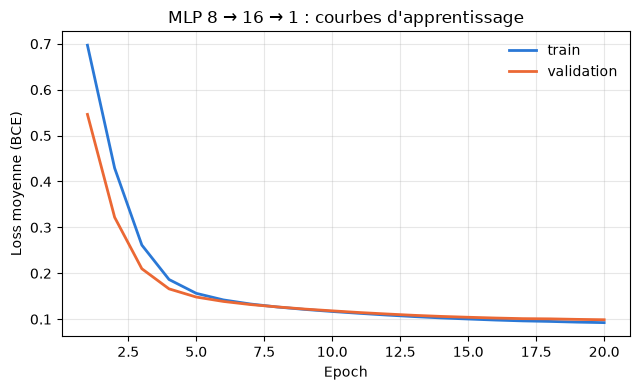

In [6]:
epochs = range(1, EPOCHS + 1)
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(epochs, history["train"], color="#2a78d6", lw=2, label="train")
ax.plot(epochs, history["val"], color="#eb6834", lw=2, label="validation")
ax.set_xlabel("Epoch"); ax.set_ylabel("Loss moyenne (BCE)")
ax.set_title("MLP 8 → 16 → 1 : courbes d'apprentissage")
ax.legend(frameon=False); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

**Lecture :** les deux losses baissent ensemble et la validation reste proche du train : **pas d'overfitting** sur 20 epochs. La courbe descend encore à la fin, donc le modèle n'a pas fini d'apprendre (c'est ce qu'on exploitera au TP 6).

## 4. Precision et recall sur la validation, comparaison au TP 3

Le modèle sort des logits. `torch.sigmoid` les transforme en **scores entre 0 et 1**, puis on applique un threshold, comme au TP 3.

In [7]:
model.eval()
with torch.no_grad():
    scores_mlp = torch.sigmoid(model(X_val_t).squeeze(1)).numpy()

# la logistic regression du TP 3, sur exactement les mêmes splits
from sklearn.pipeline import make_pipeline
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
logit = make_pipeline(clone(preprocess), LogisticRegression(max_iter=1000)).fit(X_train, Y_train)
scores_logit = logit.predict_proba(X_val)[:, 1]

rows = []
for name, s in [("logistic regression (TP 3)", scores_logit), ("MLP 16 (TP 4)", scores_mlp)]:
    for t in [0.3, 0.5]:
        p = (s >= t).astype(int)
        tn, fp, fn, tp = confusion_matrix(Y_val, p).ravel()
        rows.append({"modèle": name, "threshold": t,
                     "precision": precision_score(Y_val, p, zero_division=0),
                     "recall": recall_score(Y_val, p),
                     "pannes détectées": f"{tp} / {tp + fn}", "fausses alertes": fp})
pd.DataFrame(rows).set_index(["modèle", "threshold"]).round(3)

precision  recall pannes détectées  \
modèle                     threshold                                       
logistic regression (TP 3) 0.3            0.489   0.324          22 / 68   
                           0.5            0.727   0.235          16 / 68   
MLP 16 (TP 4)              0.3            0.533   0.353          24 / 68   
                           0.5            0.778   0.206          14 / 68   

                                      fausses alertes  
modèle                     threshold                   
logistic regression (TP 3) 0.3                     23  
                           0.5                      6  
MLP 16 (TP 4)              0.3                     21  
                           0.5                      4

## Conclusion

- Les tensors sont en `float32` (features et target), les shapes sont `[N, 8]` pour X et `[N]` pour y.
- Sur 20 epochs, les losses de train et de validation baissent ensemble : **pas d'overfitting**, et le modèle n'a pas encore convergé.
- **Comparaison au TP 3 :** le petit MLP (16 neurones, lr 1e-3, 20 epochs) donne des résultats **du même ordre** que la logistic regression, sans gain net. C'est logique : un MLP mal entraîné ou trop petit se comporte presque comme une logistic regression (un seul neurone = une logistic regression).
- Sur 68 pannes, quelques pannes de différence ne sont **pas significatives** : il faudrait plusieurs seeds pour conclure.
- Le TP 6 montre qu'un MLP **plus large et mieux entraîné** (64 neurones, lr 1e-2) bat nettement la logistic regression.